1. Считайте датасет из файла train.csv (это данные о выживаемости на Титанике) 

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('train.csv')

2. Визуализируйте распределение значений признаков Survived, Pclass, Age, Sex. Parch

C:\Users\Vlad\AppData\Local\Temp\ipykernel_25052\2499396041.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




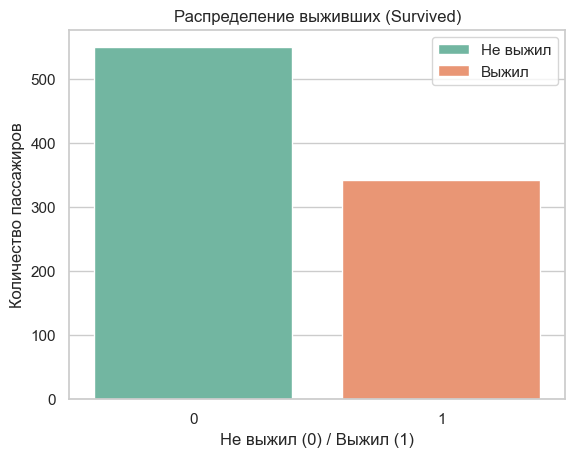

In [31]:
# Визуализация распределения признака Survived
sns.countplot(x='Survived', data=data, palette='Set2')
plt.title('Распределение выживших (Survived)')
plt.xlabel('Не выжил (0) / Выжил (1)')
plt.ylabel('Количество пассажиров')
plt.legend(['Не выжил', 'Выжил'], loc='upper right')
plt.show()

C:\Users\Vlad\AppData\Local\Temp\ipykernel_25052\542188853.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




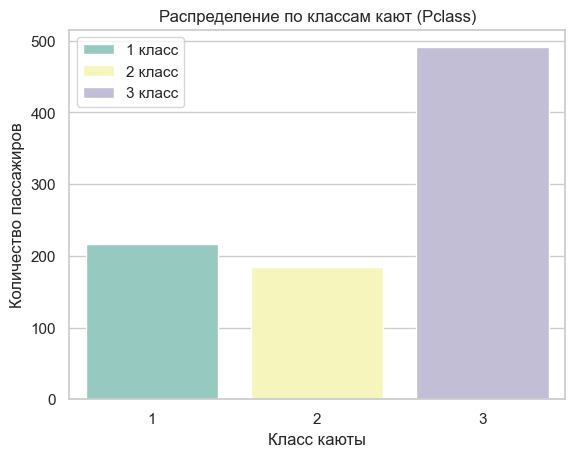

In [30]:
# Визуализация распределения признака Pclass
sns.countplot(x='Pclass', data=data, palette='Set3')
plt.title('Распределение по классам кают (Pclass)')
plt.xlabel('Класс каюты')
plt.ylabel('Количество пассажиров')
plt.legend(['1 класс', "2 класс", "3 класс"], loc = 'upper left')
plt.show()

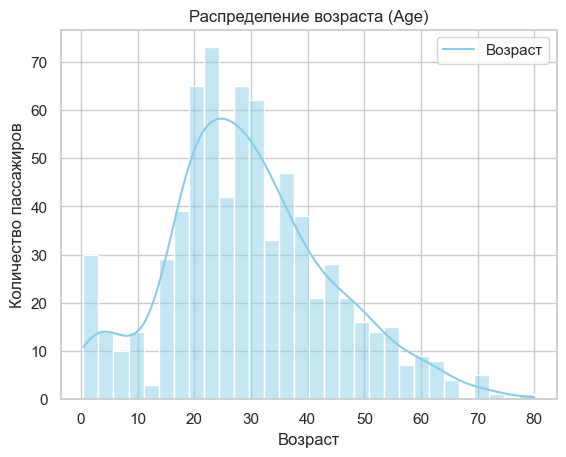

In [32]:
# Визуализация распределения признака Age
sns.histplot(data['Age'].dropna(), bins=30, kde=True, color='skyblue')
plt.title('Распределение возраста (Age)')
plt.xlabel('Возраст')
plt.ylabel('Количество пассажиров')
plt.legend(['Возраст'], loc='upper right')
plt.show()

C:\Users\Vlad\AppData\Local\Temp\ipykernel_25052\2036984835.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




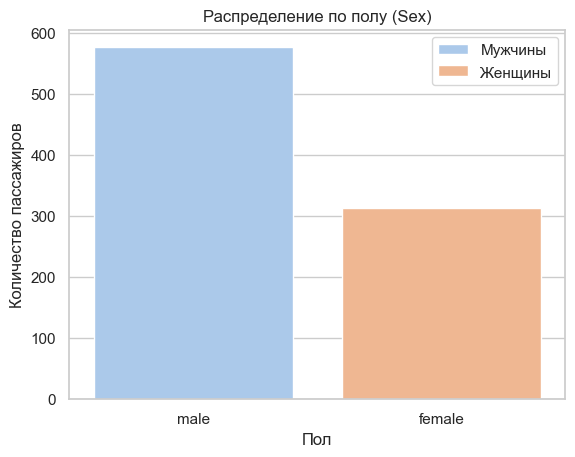

In [33]:
# Визуализация распределения признака Sex
sns.countplot(x='Sex', data=data, palette='pastel')
plt.title('Распределение по полу (Sex)')
plt.xlabel('Пол')
plt.ylabel('Количество пассажиров')
plt.legend(['Мужчины', "Женщины"])
plt.show()

C:\Users\Vlad\AppData\Local\Temp\ipykernel_25052\1962018289.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




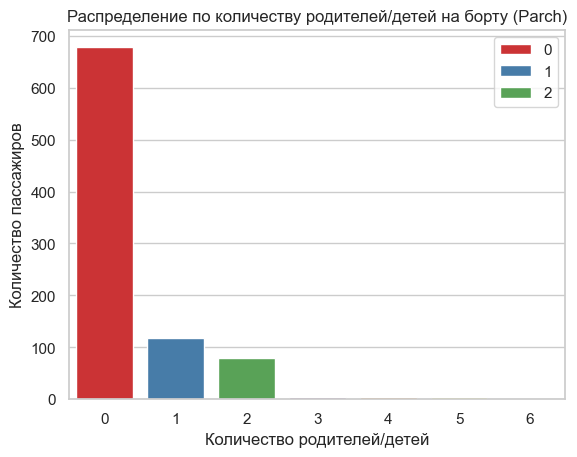

In [36]:
# Визуализация распределения признака Parch
sns.countplot(x='Parch', data=data, palette='Set1')
plt.title('Распределение по количеству родителей/детей на борту (Parch)')
plt.xlabel('Количество родителей/детей')
plt.ylabel('Количество пассажиров')
plt.legend(['0','1','2'])
plt.show()

3. Постройте график типа boxplot для столбца Age

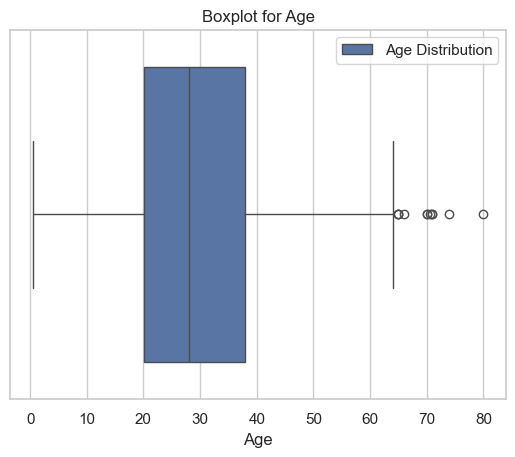

In [ ]:
age_data = data['Age'].dropna()

sns.boxplot(x=age_data)
plt.title('Boxplot for Age')
plt.xlabel('Age')
plt.legend(['Age Distribution'])
plt.show()

4. Проинтепретируйте полученный график

Минимальный возраст - около 0 лет.<br>
Первый квартиль - 25% молодых пассажиров были в возрасте 20 лет.<br>
Второй квартиль - мединное значение возраста около 27-28 лет<br>
Третий квартиль - 75% старших пассажиров были в возрасте 37-38 лет.<br>
Максимальный возраст - 80 лет (выброс)<br>

5. Постройте график типа pie chart для переменных Survived, Pclass, подпишите доли в процентах

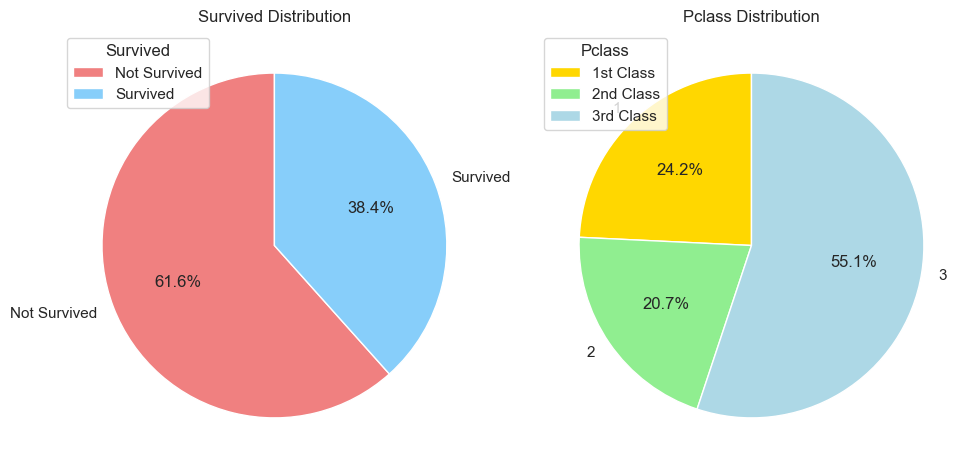

In [46]:
import matplotlib.pyplot as plt

survived_counts = data['Survived'].value_counts()
plt.figure(figsize=(10, 5))

# график Survived
plt.subplot(1, 2, 1)
plt.pie(survived_counts, labels=['Not Survived', 'Survived'], autopct='%1.1f%%', startangle=90, colors=['lightcoral', 'lightskyblue'])
plt.title('Survived Distribution')
plt.legend(survived_counts.index.map({0: 'Not Survived', 1: 'Survived'}), title='Survived', loc='upper left')

# график Pclass
pclass_counts = data['Pclass'].value_counts().sort_index()
plt.subplot(1, 2, 2)
plt.pie(pclass_counts, labels=pclass_counts.index, autopct='%1.1f%%', startangle=90, colors=['gold', 'lightgreen', 'lightblue'])
plt.title('Pclass Distribution')
plt.legend(pclass_counts.index.map({1: '1st Class', 2: '2nd Class', 3: '3rd Class'}), title='Pclass', loc='upper left')

plt.tight_layout()
plt.show()

6. Постройте график типа pairplot для всех числовых переменных датасета

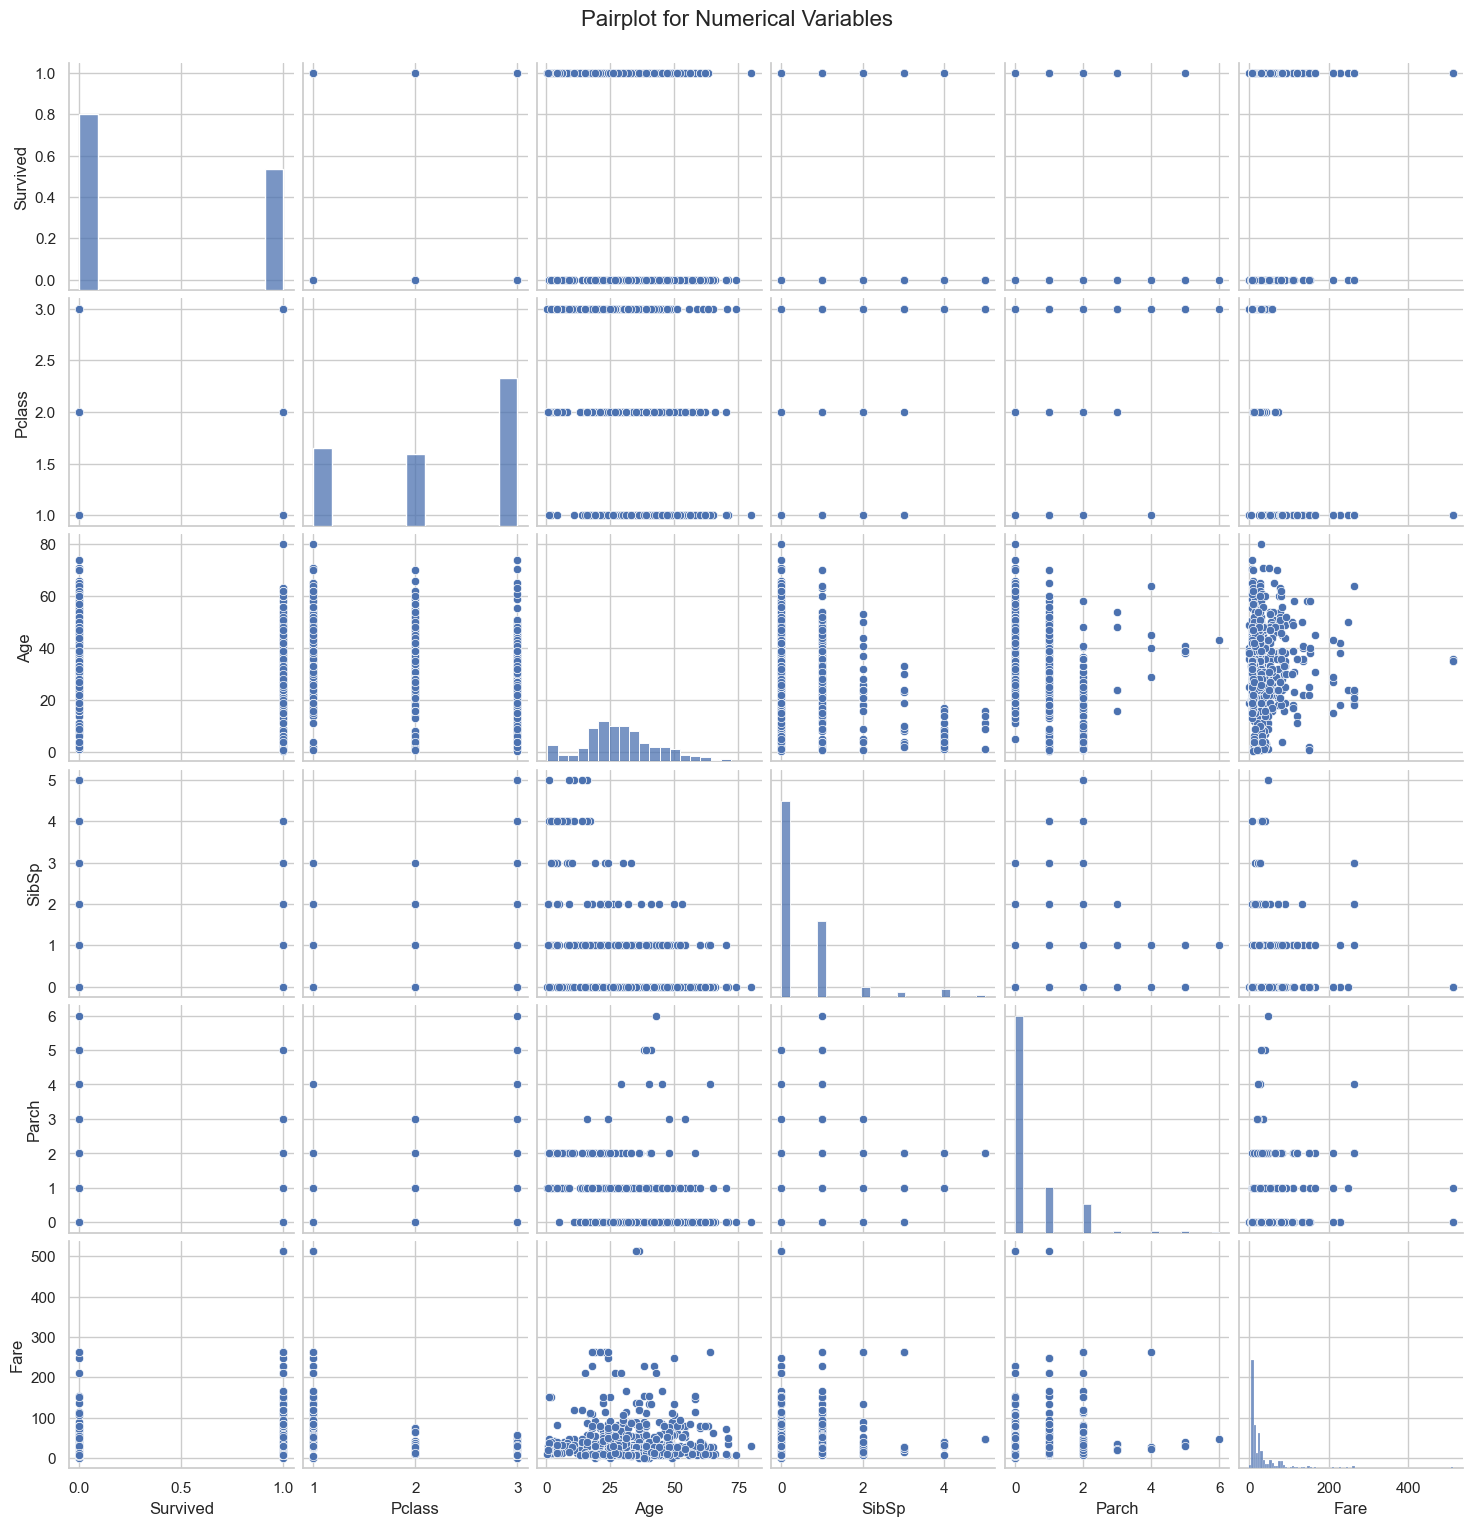

In [ ]:
numeric_columns = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

data_numeric = data[numeric_columns].dropna()

sns.pairplot(data_numeric)
plt.suptitle('Pairplot for Numerical Variables', fontsize=16, y=1.02)

plt.show()

7. Постройте интерактивный sunburst plot (визуализация иерархических данных) с помощью plotly. На первом уровне иерархии - количество пассажиров в каждом из классов, а на втором количество женщин/мужчин в этом классе

In [ ]:
import plotly.express as px
data['Pclass_Sex'] = data['Pclass'].astype(str) + ' - ' + data['Sex']

grouped_data = data.groupby(['Pclass', 'Sex']).size().reset_index(name='Count')

grouped_data.columns = ['Pclass', 'Sex', 'Count']

fig = px.sunburst(
    grouped_data,
    path=['Pclass', 'Sex'],  
    values='Count',          
    title='Sunburst Plot: Распределение пассажиров по классам и полу'
)

fig.update_traces(textinfo='label+percent entry')  
fig.update_layout(width=800, height=600)           

fig.show()